# Election survey: raw vs anonymised data

This notebook answers three questions on both the raw survey and the anonymised release, and compares the results:

* **(A)** Is there a significant difference between the political preferences in the survey and the election results, for electronic and polling-station votes?
* **(B)** Do political preferences differ significantly by demographic attributes?
* **(C)** Does the choice of voting channel differ significantly by demographic attributes?

| Data | File | Used as |
|---|---|---|
| **Raw** | `data/private_dataM.xlsx` | recoded to the same groups as the release, so both are compared like for like |
| **Anonymised** | `data/anonymised_dataM_v3.csv` | the released data, as is |
| Official results | `data/public_data_resultsM.xlsx` | the reference for question A |

Attributes that exist only in the raw data (exact age, 4 ZIP codes, marital status, citizenship) are analysed separately in section 5.

Significance level throughout: **α = 0.05**.

**How the differences are judged.** Some change is expected after anonymisation, so small differences are accepted. Each test gets one of three labels:

| Label | Meaning |
|---|---|
| **small** | same verdict at α = 0.05, and the effect moved little |
| **large effect change** | same verdict, but the effect moved a lot: a share or Cramér's V by more than 0.10, or an odds ratio by more than a factor of 2 |
| **verdict changed** | significant in one dataset and not in the other |

Differences are called **too large** for a question only when a verdict changes in that question's main tests: the channel comparison in (A) or the single-attribute tests in (B) and (C). Changes inside a regression are written out but accepted, as long as the main tests agree.

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from scipy import stats
from scipy.special import gammaln
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
ALPHA = 0.05
CATS = ["Red", "Green", "Invalid vote"]
STYLE = {"raw": {"color": "#1f77b4", "marker": "o"},        # colour + marker, so colour is never the only cue
         "anonymised": {"color": "#ff7f0e", "marker": "D"}}
OFFSET = {"raw": -0.14, "anonymised": 0.14}

priv = pd.read_excel("data/private_dataM.xlsx")
anon_file = pd.read_csv("data/anonymised_dataM_v3.csv")
results = pd.read_excel("data/public_data_resultsM.xlsx").rename(columns={"Unnamed: 0": "unit"})
print(priv.shape, anon_file.shape)

(200, 9) (200, 6)


## 1. Preparing the data
The raw survey gets the same coding as the release:
* **Age** becomes 20-39 / 40-59 / 60+ (at 2025-07-01). The rank tests and regressions use the band as a rank of 0, 1 or 2.
* **ZIP** becomes two regions, 2100-2200 and 2300-2400.
* **Education** becomes 4 levels. *Not stated* (n = 3) is excluded, as it has no place in the ordering.

Blanks in the anonymised data (`NA`) are left out test by test. In the regressions they form an *Unknown* level, so rows are kept.

In [2]:
REGION = {2100: "2100-2200", 2200: "2100-2200", 2300: "2300-2400", 2400: "2300-2400"}
EDU_RELEASE = {
    "Primary education": "Primary",
    "Upper secondary education": "Secondary/VET", "Vocational Education and Training (VET)": "Secondary/VET",
    "Short cycle higher education": "Short/medium higher", "Vocational bachelors educations": "Short/medium higher",
    "Bachelors programmes": "Short/medium higher",
    "Masters programmes": "Long higher", "PhD programmes": "Long higher",
    "Not stated": "Not stated",
}
AGE_BANDS = ["20-39", "40-59", "60+"]
EDU_LEVELS = ["Primary", "Secondary/VET", "Short/medium higher", "Long higher"]
ORDERS = {"sex": ["Female", "Male"], "age_group": AGE_BANDS, "education": EDU_LEVELS,
          "region": ["2100-2200", "2300-2400"], "channel": ["Paper", "Electronic"]}


def finish(df):
    df = df.copy()
    df["channel"] = df["evote"].map({0: "Paper", 1: "Electronic"})
    df.loc[df["education"] == "Not stated", "education"] = np.nan
    df["age_rank"] = df["age_group"].map({a: i for i, a in enumerate(AGE_BANDS)})
    df["edu_rank"] = df["education"].map({e: i for i, e in enumerate(EDU_LEVELS)})
    return df


exact_age = ((pd.Timestamp("2025-07-01") - priv["dob"]).dt.days / 365.25).astype(int)
raw = finish(pd.DataFrame({
    "sex": priv["sex"],
    "age_group": pd.cut(exact_age, [0, 39, 59, 200], labels=AGE_BANDS).astype(str),
    "region": priv["zip"].map(REGION),
    "education": priv["education"].map(EDU_RELEASE),
    "evote": priv["evote"], "party": priv["party"],
}))
anon = finish(anon_file)
DATA = {"raw": raw, "anonymised": anon}
pd.DataFrame({k: v["party"].value_counts() for k, v in DATA.items()}).fillna(0).astype(int).reindex(CATS)

,raw,anonymised
party,,
Red,71,72
Green,127,128
Invalid vote,2,0


## 2. What the anonymisation changed
Each panel shows the share of rows per value. For education, *(blank)* is the 3 people who answered *Not stated*, in both datasets. The overall distributions barely move, so the release still looks like the survey. The differences that matter are in how columns relate to each other, which sections 3–5 test.

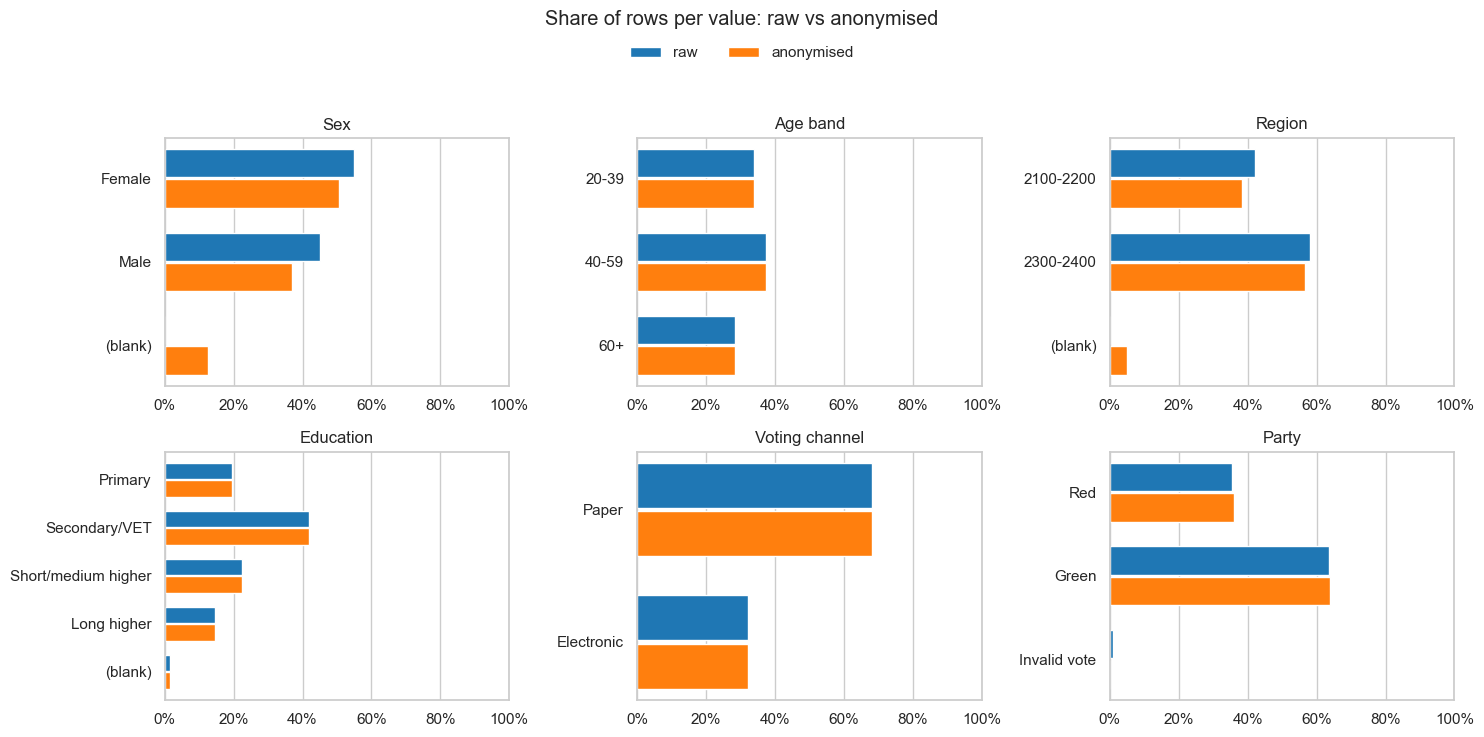

In [3]:
OVERVIEW = {"sex": "Sex", "age_group": "Age band", "region": "Region", "education": "Education",
            "channel": "Voting channel", "party": "Party"}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (col, title) in zip(axes.flat, OVERVIEW.items()):
    order = ORDERS.get(col, CATS) + ["(blank)"]
    shares = pd.DataFrame({k: v[col].fillna("(blank)").value_counts(normalize=True) for k, v in DATA.items()})
    shares = shares.reindex([o for o in order if o in shares.index]).fillna(0)
    y = np.arange(len(shares))
    for name, style in STYLE.items():
        ax.barh(y + OFFSET[name] * 1.3, shares[name], height=0.34, color=style["color"], label=name)
    ax.set_yticks(y); ax.set_yticklabels(shares.index); ax.invert_yaxis()
    ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.set_xlim(0, 1)
    ax.set_title(title); ax.grid(axis="y", visible=False)
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.95))
fig.suptitle("Share of rows per value: raw vs anonymised")
plt.tight_layout(rect=(0, 0, 1, 0.91)); plt.show()

### The blanks are not random
Blanks fall mostly on e-voters, the rarer group. **Every blanked region belongs to an e-voter aged 40 or over**, which matters for the channel regression in section 4.

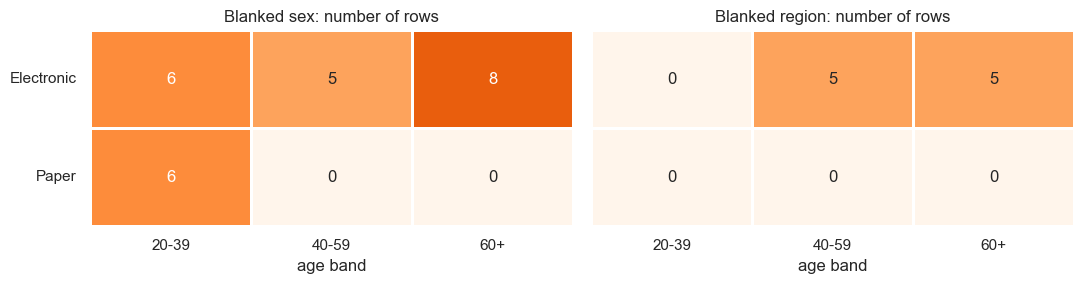

In [4]:
blanks = pd.concat({col: anon[col].isna().groupby([anon["channel"], anon["age_group"]]).sum().unstack()
                    for col in ["sex", "region"]}, axis=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, col in zip(axes, ["sex", "region"]):
    sns.heatmap(blanks[col].astype(int), annot=True, fmt="d", cmap="Oranges", vmin=0, vmax=12, cbar=False,
                linewidths=2, linecolor="white", ax=ax)
    ax.set_title(f"Blanked {col}: number of rows"); ax.set_xlabel("age band"); ax.set_ylabel("")
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout(); plt.show()

## Shared test functions
The tests are the same as in `analysis_anonymised.ipynb`. `drop_separating` handles one new case: if every row in an *Unknown* level has the same outcome, the regression has no valid solution, so those rows are left out of that model and the notebook says so.

In [5]:
def multinomial_mc_p(obs, probs, rng, n_sim=200_000):
    obs = np.asarray(obs); probs = np.asarray(probs, float)
    def loglik(x):
        return (x * np.log(np.where(probs > 0, probs, 1))).sum(axis=-1) - gammaln(x + 1).sum(axis=-1)
    sims = rng.multinomial(obs.sum(), probs, size=n_sim)
    return (np.sum(loglik(sims) <= loglik(obs) + 1e-9) + 1) / (n_sim + 1)


def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))


def perm_chi2_p(x, y, n_perm=20_000, seed=0):
    r = np.random.default_rng(seed)
    obs = stats.chi2_contingency(pd.crosstab(x, y), correction=False)[0]
    y = np.asarray(y); x = np.asarray(x)
    cnt = 0
    for _ in range(n_perm):
        cnt += stats.chi2_contingency(pd.crosstab(x, r.permutation(y)), correction=False)[0] >= obs - 1e-12
    return (cnt + 1) / (n_perm + 1)


def assoc_table(df, outcome, attrs):
    rows = []
    for a in attrs:
        d = df[[a, outcome]].dropna()
        ct = pd.crosstab(d[a], d[outcome])
        ct = ct.loc[ct.sum(axis=1) > 0]
        chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
        small = (exp < 5).mean()
        if small > 0.2:
            if ct.shape == (2, 2):
                p_used, test = stats.fisher_exact(ct)[1], "Fisher exact"
            else:
                p_used, test = perm_chi2_p(d[a], d[outcome]), "permutation chi2"
        else:
            p_used, test = p, "chi2"
        rows.append({"attribute": a, "levels": ct.shape[0], "n": int(ct.values.sum()), "test used": test,
                     "p": p_used, "Cramer's V": cramers_v(ct)})
    out = pd.DataFrame(rows).set_index("attribute")
    out["p Holm"] = multipletests(out["p"], method="holm")[1]
    return out


def mwu_table(df, outcome, groups, ranks):
    rows = []
    for var in ranks:
        d = df.dropna(subset=[var, outcome])
        a, b = d.loc[d[outcome] == groups[0], var], d.loc[d[outcome] == groups[1], var]
        u = stats.mannwhitneyu(a, b, alternative="two-sided")
        rows.append({"variable": var, f"mean {groups[0]}": a.mean(), f"mean {groups[1]}": b.mean(), "p": u.pvalue,
                     "rank-biserial r": 1 - 2 * u.statistic / (len(a) * len(b))})
    return pd.DataFrame(rows).set_index("variable")


def fit_logit(formula, data):
    m = smf.logit(formula, data=data).fit(disp=False)
    ci = np.exp(m.conf_int())
    return pd.DataFrame({"OR": np.exp(m.params), "CI low": ci[0], "CI high": ci[1], "p": m.pvalues}).drop("Intercept")


def side_by_side(tables, cols):
    """Stack the same columns of several result tables next to each other: (version, column)."""
    return pd.concat({k: t[cols] for k, t in tables.items()}, axis=1)

In [6]:
def wilson(successes, n):
    lo, hi = proportion_confint(successes, n, method="wilson")
    return successes / n, lo, hi


def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"


def share_panels(outcome, value, attrs, titles, xlabel, suptitle, tables, keep=None):
    """Share of `value` per attribute level with 95% Wilson intervals, one panel per attribute."""
    ncol = 2 if len(attrs) == 4 else 3
    nrow = int(np.ceil(len(attrs) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 3.4 * nrow), squeeze=False)
    for ax, a in zip(axes.flat, attrs):
        levels = ORDERS[a]
        for name, style in STYLE.items():
            d = DATA[name] if keep is None else keep[name]
            d = d[[a, outcome]].dropna()
            g = d.groupby(a)[outcome].agg(lambda s: (s == value).sum()).reindex(levels)
            n = d.groupby(a)[outcome].size().reindex(levels)
            p, lo, hi = wilson(g.astype(float), n.astype(float))
            y = np.arange(len(levels)) + OFFSET[name]
            ax.errorbar(p, y, xerr=[p - lo, hi - p], fmt="none", ecolor=style["color"], capsize=3, lw=1.5)
            ax.scatter(p, y, s=55, label=name, edgecolor="white", linewidth=1.2, zorder=3, **style)
        ax.set_yticks(range(len(levels))); ax.set_yticklabels(levels); ax.invert_yaxis()
        ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.set_xlabel(xlabel)
        p_r, p_a = tables["raw"]["p Holm"][a], tables["anonymised"]["p Holm"][a]
        ax.set_title(f"{titles[a]}\nHolm p: raw {fmt_p(p_r)} | anonymised {fmt_p(p_a)}", fontsize=11)
    for ax in axes.flat[len(attrs):]:
        ax.axis("off")
    handles, names = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, names, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.97))
    fig.suptitle(suptitle)
    plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()


def pretty(term):
    m = re.match(r"C\((\w+).*\)\[T\.(.+)\]", term)
    return f"{m.group(1)}: {m.group(2)}" if m else term.replace("age_rank", "age (per band)")


def forest_compare(tables, title):
    terms = list(tables["raw"].index) + [t for t in tables["anonymised"].index if t not in tables["raw"].index]
    fig, ax = plt.subplots(figsize=(9.5, 0.5 * len(terms) + 1.8))
    for name, style in STYLE.items():
        t = tables[name].reindex(terms)
        y = np.arange(len(terms)) + OFFSET[name]
        ax.errorbar(t["OR"], y, xerr=[t["OR"] - t["CI low"], t["CI high"] - t["OR"]], fmt="none",
                    ecolor=style["color"], capsize=3, lw=1.5)
        ax.scatter(t["OR"], y, s=45, label=name, edgecolor="white", linewidth=1.2, zorder=3, **style)
    ax.axvline(1, color="#555555", ls="--", lw=1); ax.set_xscale("log")
    ax.set_yticks(range(len(terms))); ax.set_yticklabels([pretty(t) for t in terms]); ax.invert_yaxis()
    ax.set_xlabel("odds ratio (log scale, 95% CI); the dashed line means no effect"); ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -1.0 / fig.get_figheight()), ncol=2, frameon=False)
    plt.tight_layout(); plt.show()


def prep_lr(df):
    d = df.dropna(subset=["education"]).copy()
    for c in ["sex", "region"]:
        d[c] = d[c].fillna("Unknown")
    return d


def drop_separating(d, outcome, label):
    for c in ["sex", "region"]:
        if (d[c] == "Unknown").any() and d.loc[d[c] == "Unknown", outcome].nunique() == 1:
            print(f"{label}: all {(d[c] == 'Unknown').sum()} rows with blank {c} have the same outcome, left out of this model")
            d = d[d[c] != "Unknown"]
    return d

---
## 3. Question A: survey vs official results
The official results are the population and the survey is a sample. For each group the test is whether the survey's distribution equals the official one:
* the **exact binomial test** on the Red share among valid votes, the main test here;
* an **exact multinomial test** on Red / Green / Invalid. Because the anonymised data has no invalid votes, this test behaves differently there: it now also counts the missing invalid votes as a difference.

Paper votes are also tested per region, adding the official ZIP results together. Blanked regions are left out of those two rows.

In [7]:
res = results.set_index("unit")[["Red", "Green", "Invalid ballots"]]
res.columns = CATS
res.loc["Polling stations (all)"] = res.filter(like="Polling station", axis=0).sum()
for rg in ORDERS["region"]:
    res.loc[f"Region {rg}"] = res.loc[[f"Polling station: ZIP {z}" for z, r in REGION.items() if r == rg]].sum()
res.loc["All votes"] = res.loc[["E-votes", "Polling stations (all)"]].sum()


def compare(sub, official_row, label, rng):
    obs = sub["party"].value_counts().reindex(CATS, fill_value=0)
    p_off = res.loc[official_row, CATS] / res.loc[official_row, CATS].sum()
    valid = obs["Red"] + obs["Green"]
    red_off = res.loc[official_row, "Red"] / (res.loc[official_row, "Red"] + res.loc[official_row, "Green"])
    bt = stats.binomtest(int(obs["Red"]), int(valid), red_off)
    share, lo, hi = wilson(obs["Red"], valid)
    return {"group": label, "n": int(obs.sum()), "Red/Green/Invalid": "/".join(str(obs[c]) for c in CATS),
            "official Red share": red_off, "survey Red share": share, "CI low": lo, "CI high": hi,
            "p binomial": bt.pvalue, "p exact multinomial": multinomial_mc_p(obs.values, p_off.values, rng)}


def run_A(df):
    rng = np.random.default_rng(42)
    rows = [compare(df[df.evote == 1], "E-votes", "Electronic", rng),
            compare(df[df.evote == 0], "Polling stations (all)", "Paper (all)", rng)]
    for rg in ORDERS["region"]:
        rows.append(compare(df[(df.evote == 0) & (df.region == rg)], f"Region {rg}", f"Paper {rg}", rng))
    rows.append(compare(df, "All votes", "All votes", rng))
    out = pd.DataFrame(rows).set_index("group")
    out["p binomial Holm"] = multipletests(out["p binomial"], method="holm")[1]
    return out


A = {k: run_A(v) for k, v in DATA.items()}
side_by_side(A, ["n", "Red/Green/Invalid", "survey Red share", "official Red share", "p binomial", "p binomial Holm",
                 "p exact multinomial"]).round(4)

raw                                                                                                      anonymised                                                                   \
                   n Red/Green/Invalid survey Red share official Red share p binomial p binomial Holm p exact multinomial          n Red/Green/Invalid survey Red share official Red share p binomial   
group                                                                                                                                                                                                   
Electronic        64           18/46/0           0.2812             0.3188     0.5926           1.000              0.6800         64           18/46/0           0.2812             0.3188     0.5926   
Paper (all)      136           53/81/2           0.3955             0.3482     0.2764           1.000              0.5146        136           54/82/0           0.3971             0.3482     0.2423   
Paper 2100-2200   59           15/43/1           0.2586             0.2804     0.7720           1.000              0.9161         59           15/44/0           0.2542             0.2804     0.7722   
Paper 2300-2400   77           38/38/1           0.5000             0.3957     0.0778           0.389              0.1554         77           39/38/0           0.5065             0.3957     0.0615   
All votes        200          71/127/2           0.3586             0.3387     0.5489           1.000              0.7148        200          72/128/0           0.3600             0.3387     0.5501   

                                                     
                p binomial Holm p exact multinomial  
group                                                
Electronic               1.0000              0.6800  
Paper (all)              0.9693              0.1820  
Paper 2100-2200          1.0000              0.7334  
Paper 2300-2400          0.3074              0.1056  
All votes                1.0000              0.1179

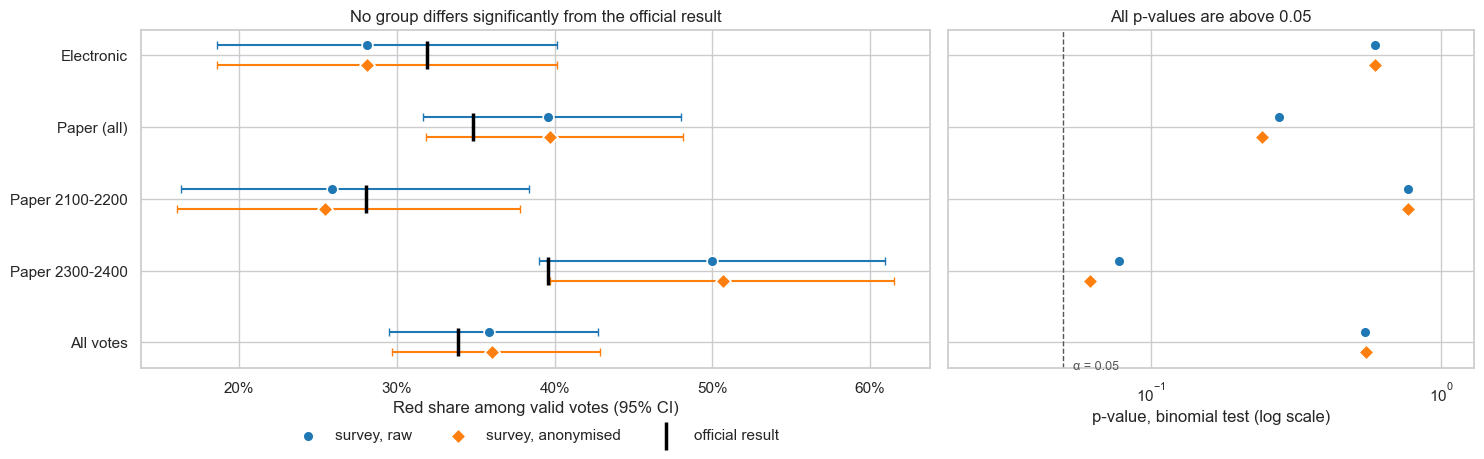

In [8]:
groups = list(A["raw"].index)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]}, sharey=True)
ax = axes[0]
for name, style in STYLE.items():
    t = A[name]
    y = np.arange(len(groups)) + OFFSET[name]
    ax.errorbar(t["survey Red share"], y, xerr=[t["survey Red share"] - t["CI low"], t["CI high"] - t["survey Red share"]],
                fmt="none", ecolor=style["color"], capsize=3, lw=1.5)
    ax.scatter(t["survey Red share"], y, s=60, label=f"survey, {name}", edgecolor="white", linewidth=1.2, zorder=3, **style)
ax.scatter(A["raw"]["official Red share"], range(len(groups)), marker="|", s=420, color="black", linewidth=2.5,
           zorder=4, label="official result")
ax.set_yticks(range(len(groups))); ax.set_yticklabels(groups); ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.set_xlabel("Red share among valid votes (95% CI)")
ax.set_title("No group differs significantly from the official result")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)

ax = axes[1]
for name, style in STYLE.items():
    ax.scatter(A[name]["p binomial"], np.arange(len(groups)) + OFFSET[name], s=60, edgecolor="white", linewidth=1.2,
               zorder=3, **style)
ax.axvline(ALPHA, color="#555555", ls="--", lw=1); ax.set_xscale("log"); ax.set_xlim(0.02, 1.3)
ax.text(ALPHA * 1.08, len(groups) - 0.62, "α = 0.05", color="#555555", fontsize=9)
ax.set_xlabel("p-value, binomial test (log scale)"); ax.set_title("All p-values are above 0.05")
plt.tight_layout(); plt.show()

---
## 4. Questions B and C: raw vs anonymised
### Question B: party vs demographics
Outcome: Red vs Green among valid votes. The tests are χ² (with Fisher or permutation fallbacks for small counts) with Cramér's V and Holm correction, Mann–Whitney for the ordered attributes, and a logistic regression that holds the other attributes constant.

In [9]:
B_ATTRS = ["sex", "age_group", "education", "region", "channel"]
TITLES = {"sex": "Sex", "age_group": "Age band", "education": "Education", "region": "Region", "channel": "Voting channel"}
valid = {k: v[v["party"].isin(["Red", "Green"])].assign(red=lambda d: (d["party"] == "Red").astype(int))
         for k, v in DATA.items()}
B = {k: assoc_table(v, "party", B_ATTRS) for k, v in valid.items()}
side_by_side(B, ["n", "test used", "p", "p Holm", "Cramer's V"]).round(4)

raw                                      anonymised                                     
             n test used       p  p Holm Cramer's V          n test used       p  p Holm Cramer's V
attribute                                                                                          
sex        198      chi2  0.2436  0.2436     0.0829        175      chi2  0.5282  0.5282     0.0477
age_group  198      chi2  0.0000  0.0000     0.3688        200      chi2  0.0000  0.0000     0.3436
education  195      chi2  0.0000  0.0001     0.3575        197      chi2  0.0080  0.0239     0.2451
region     198      chi2  0.0034  0.0101     0.2084        190      chi2  0.0013  0.0051     0.2337
channel    198      chi2  0.1168  0.2337     0.1114        200      chi2  0.1115  0.2229     0.1125

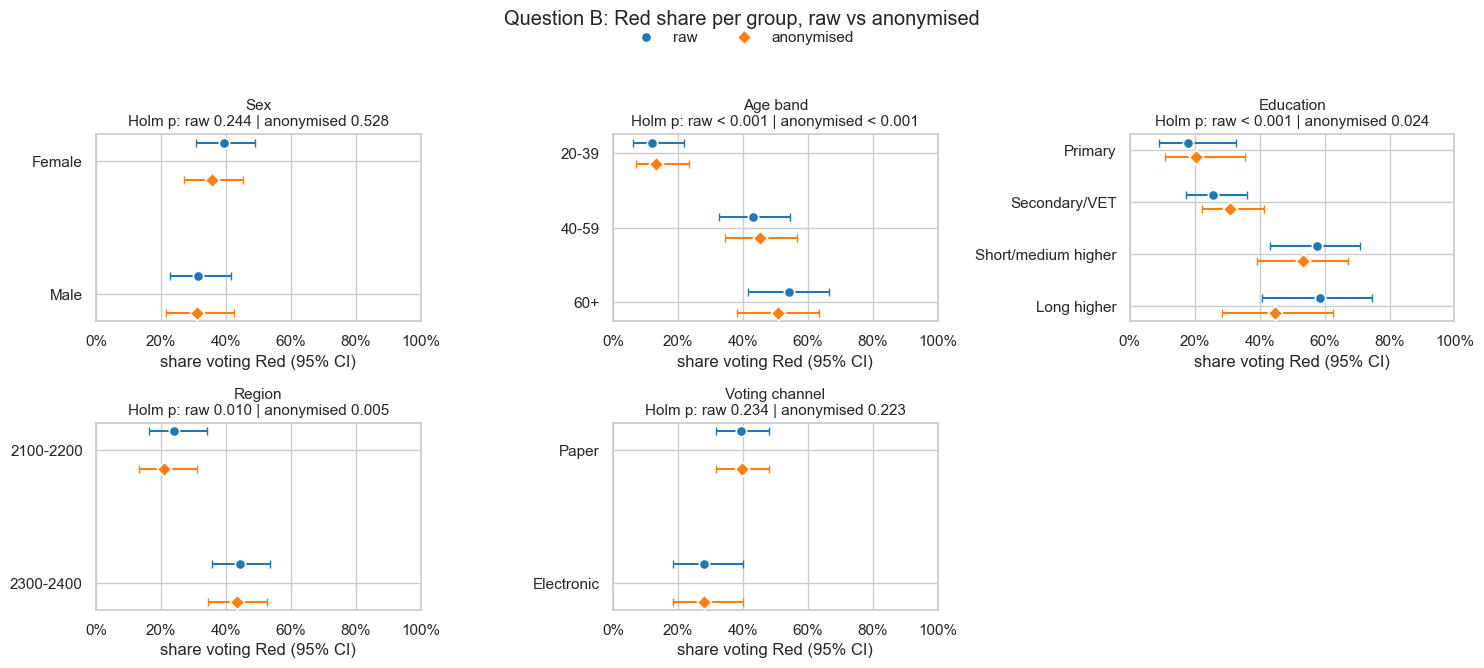

In [10]:
share_panels("party", "Red", B_ATTRS, TITLES, "share voting Red (95% CI)",
             "Question B: Red share per group, raw vs anonymised", B, keep=valid)

In [11]:
B_num = {k: mwu_table(v, "party", ["Red", "Green"], ["age_rank", "edu_rank"]) for k, v in valid.items()}
side_by_side(B_num, ["p", "rank-biserial r"]).round(4)

raw                 anonymised                
            p rank-biserial r          p rank-biserial r
variable                                                
age_rank  0.0         -0.4040     0.0000         -0.3617
edu_rank  0.0         -0.3847     0.0019         -0.2533

raw         anonymised        
                                                         OR       p         OR       p
C(sex, Treatment('Female'))[T.Male]                  0.3761  0.0106     0.6261  0.2139
C(education, Treatment('Primary'))[T.Long higher]   14.8714  0.0001     4.5993  0.0112
C(education, Treatment('Primary'))[T.Secondary/...   2.7972  0.0618     2.5165  0.0695
C(education, Treatment('Primary'))[T.Short/medi...  16.6627  0.0000     6.8932  0.0006
C(region)[T.2300-2400]                               1.8971  0.1028     2.5266  0.0212
C(channel, Treatment('Paper'))[T.Electronic]         0.5981  0.2198     0.3389  0.0204
age_rank                                             3.3054  0.0000     1.9874  0.0082
C(sex, Treatment('Female'))[T.Unknown]                  NaN     NaN     1.4353  0.5881
C(region)[T.Unknown]                                    NaN     NaN     6.1775  0.0964

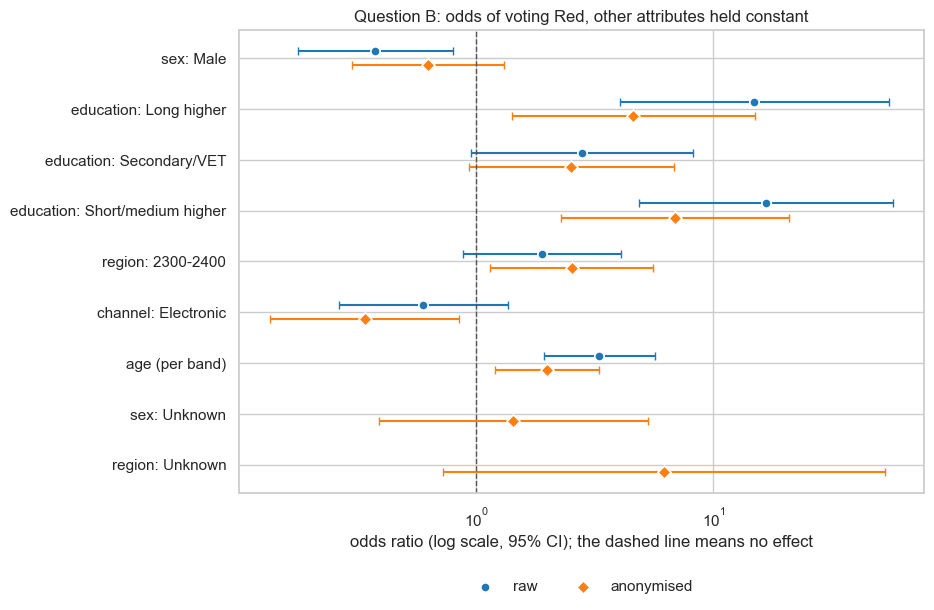

In [12]:
RHS = "age_rank + C(sex, Treatment('Female')) + C(education, Treatment('Primary')) + C(region)"
CHANNEL = " + C(channel, Treatment('Paper'))"
B_logit = {k: fit_logit("red ~ " + RHS + CHANNEL, drop_separating(prep_lr(valid[k]), "red", k)) for k in DATA}
display(side_by_side(B_logit, ["OR", "p"]).round(4))
forest_compare(B_logit, "Question B: odds of voting Red, other attributes held constant")

### Question C: voting channel vs demographics
Outcome: electronic vs paper, with the same tests as question B.

In [13]:
C_ATTRS = ["sex", "age_group", "education", "region"]
C_assoc = {k: assoc_table(v, "channel", C_ATTRS) for k, v in DATA.items()}
side_by_side(C_assoc, ["n", "test used", "p", "p Holm", "Cramer's V"]).round(4)

raw                                      anonymised                                     
             n test used       p  p Holm Cramer's V          n test used       p  p Holm Cramer's V
attribute                                                                                          
sex        200      chi2  0.9514  1.0000     0.0043        175      chi2  0.7188  0.7188     0.0272
age_group  200      chi2  0.0004  0.0017     0.2788        200      chi2  0.0004  0.0017     0.2788
education  197      chi2  0.0782  0.2346     0.1859        197      chi2  0.0782  0.2346     0.1859
region     200      chi2  0.5637  1.0000     0.0408        190      chi2  0.2032  0.4063     0.0923

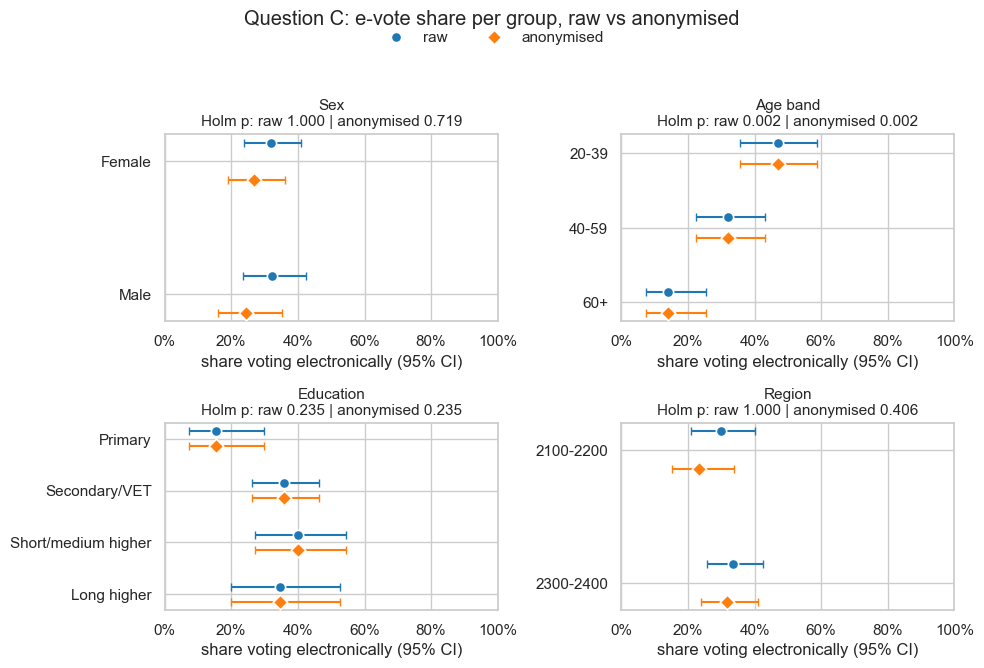

In [14]:
share_panels("channel", "Electronic", C_ATTRS, TITLES, "share voting electronically (95% CI)",
             "Question C: e-vote share per group, raw vs anonymised", C_assoc)

raw                 anonymised                
               p rank-biserial r          p rank-biserial r
variable                                                   
age_rank  0.0001          0.3235     0.0001          0.3235
edu_rank  0.0534         -0.1614     0.0534         -0.1614

anonymised: all 10 rows with blank region have the same outcome, left out of this model


raw         anonymised        
                                                        OR       p         OR       p
C(sex, Treatment('Female'))[T.Male]                 0.9838  0.9609     1.1177  0.7790
C(education, Treatment('Primary'))[T.Long higher]   2.9507  0.0818     2.6740  0.1446
C(education, Treatment('Primary'))[T.Secondary/...  3.2422  0.0244     2.7617  0.0717
C(education, Treatment('Primary'))[T.Short/medi...  4.1482  0.0125     3.1916  0.0658
C(region)[T.2300-2400]                              2.1060  0.0398     4.4479  0.0015
age_rank                                            0.3664  0.0000     0.1888  0.0000
C(sex, Treatment('Female'))[T.Unknown]                 NaN     NaN     1.3459  0.6861

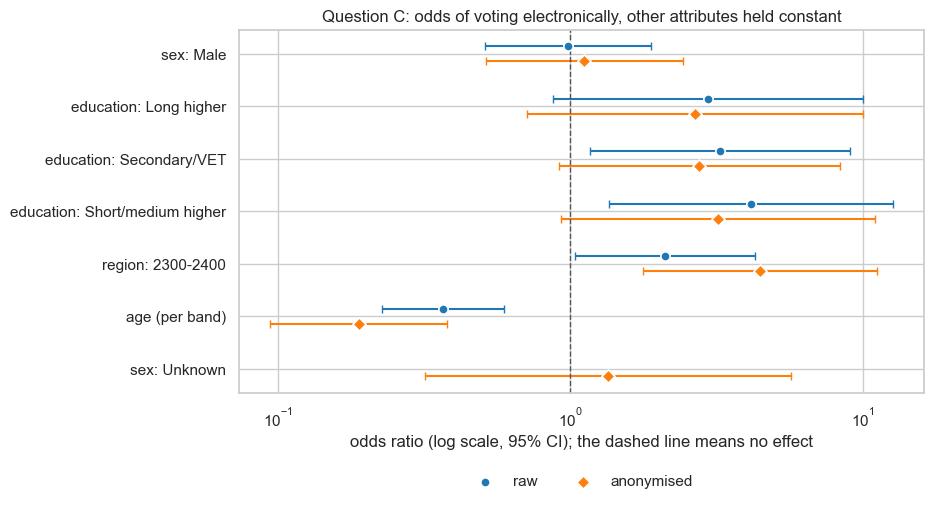

In [15]:
C_num = {k: mwu_table(v, "channel", ["Electronic", "Paper"], ["age_rank", "edu_rank"]) for k, v in DATA.items()}
display(side_by_side(C_num, ["p", "rank-biserial r"]).round(4))

C_logit = {k: fit_logit("evote ~ " + RHS, drop_separating(prep_lr(v), "evote", k)) for k, v in DATA.items()}
display(side_by_side(C_logit, ["OR", "p"]).round(4))
forest_compare(C_logit, "Question C: odds of voting electronically, other attributes held constant")

**A check on this regression.** All 10 rows with a blank region are e-voters aged 40+, so they had to be left out of the anonymised model, and that removes older e-voters only. Dropping region from the model keeps all rows, which shows how much of the age and region result comes from this.

In [16]:
SIMPLE = "age_rank + C(sex, Treatment('Female')) + C(education, Treatment('Primary'))"
C_simple = {k: fit_logit("evote ~ " + SIMPLE, prep_lr(v)) for k, v in DATA.items()}
side_by_side(C_simple, ["OR", "p"]).round(4)

raw         anonymised        
                                                        OR       p         OR       p
C(sex, Treatment('Female'))[T.Male]                 0.9562  0.8914     0.9147  0.8123
C(education, Treatment('Primary'))[T.Long higher]   3.1241  0.0640     3.2505  0.0663
C(education, Treatment('Primary'))[T.Secondary/...  3.0132  0.0327     2.8346  0.0526
C(education, Treatment('Primary'))[T.Short/medi...  4.0660  0.0131     2.7000  0.1006
age_rank                                            0.4335  0.0002     0.4109  0.0002
C(sex, Treatment('Female'))[T.Unknown]                 NaN     NaN     9.6425  0.0001

---
## 5. Only possible on the raw data
These attributes are not in the release, so the anonymised data cannot answer them. All were tested with the raw data at full detail.

In [17]:
only_raw = pd.DataFrame({
    "marital_status": priv["marital_status"],
    "citizen": np.where(priv["citizenship"] == "Denmark", "Danish", "Non-Danish"),
    "zip": priv["zip"].astype(str),
    "party": priv["party"], "channel": raw["channel"], "age": exact_age,
})
only_valid = only_raw[only_raw["party"].isin(["Red", "Green"])]
extra = pd.concat({"B: party": assoc_table(only_valid, "party", ["marital_status", "citizen", "zip"]),
                   "C: channel": assoc_table(only_raw, "channel", ["marital_status", "citizen", "zip"])})
display(extra[["n", "test used", "p", "p Holm", "Cramer's V"]].round(4))

rng = np.random.default_rng(42)
zip_rows = [compare(priv.assign(zip_s=priv["zip"].astype(str)).query("evote == 0 and zip_s == @z"),
                    f"Polling station: ZIP {z}", f"Paper ZIP {z}", rng) for z in ["2100", "2200", "2300", "2400"]]
display(pd.DataFrame(zip_rows).set_index("group")[["n", "survey Red share", "official Red share", "p binomial"]].round(4))
pd.DataFrame({"B: party": mwu_table(only_valid, "party", ["Red", "Green"], ["age"]).iloc[0],
              "C: channel": mwu_table(only_raw, "channel", ["Electronic", "Paper"], ["age"]).iloc[0]}).T[["p", "rank-biserial r"]].round(4)

n         test used       p  p Holm  Cramer's V
           attribute                                                        
B: party   marital_status  198  permutation chi2  0.0813  0.1626      0.1832
           citizen         198      Fisher exact  0.2302  0.2302      0.0994
           zip             198              chi2  0.0009  0.0027      0.2883
C: channel marital_status  200  permutation chi2  0.1255  0.3766      0.1698
           citizen         200      Fisher exact  0.7711  0.7711      0.0218
           zip             200              chi2  0.3201  0.6401      0.1324

,n,survey Red share,official Red share,p binomial
group,,,,
Paper ZIP 2100,19,0.1579,0.2195,0.7814
Paper ZIP 2200,40,0.3077,0.3237,1.0000
Paper ZIP 2300,33,0.6250,0.4671,0.0785
Paper ZIP 2400,44,0.4091,0.3490,0.4304


,p,rank-biserial r
B: party,0.0000,-0.4557
C: channel,0.0002,0.3317


---
## 6. Comparing raw and anonymised results
Every test from sections 3 and 4 appears once below, and is labelled with the rule from the top of this notebook.

In [18]:
def label(p_raw, p_anon, eff_raw, eff_anon, kind):
    if (p_raw < ALPHA) != (p_anon < ALPHA):
        return "verdict changed"
    if pd.notna(eff_raw):
        big = max(eff_raw / eff_anon, eff_anon / eff_raw) > 2 if kind == "odds ratio" else abs(eff_raw - eff_anon) > 0.10
        if big:
            return "large effect change"
    return "small"


def rows_for(question, family, tables, p_col, eff_col, kind, main):
    a, b = tables["raw"], tables["anonymised"]
    out = []
    for term in a.index.intersection(b.index):
        er, ea = (a[eff_col][term], b[eff_col][term]) if eff_col else (np.nan, np.nan)
        out.append({"question": question, "test": family, "term": pretty(term), "main test": main,
                    "p raw": a[p_col][term], "p anonymised": b[p_col][term], "effect": kind,
                    "effect raw": er, "effect anonymised": ea,
                    "label": label(a[p_col][term], b[p_col][term], er, ea, kind)})
    return out


checks = pd.DataFrame(
    rows_for("A", "binomial", A, "p binomial", "survey Red share", "Red share", True)
    + rows_for("A", "multinomial", A, "p exact multinomial", None, "", False)
    + rows_for("B", "single attribute (Holm)", B, "p Holm", "Cramer's V", "Cramér's V", True)
    + rows_for("B", "rank test", B_num, "p", "rank-biserial r", "rank-biserial r", True)
    + rows_for("B", "regression", B_logit, "p", "OR", "odds ratio", False)
    + rows_for("C", "single attribute (Holm)", C_assoc, "p Holm", "Cramer's V", "Cramér's V", True)
    + rows_for("C", "rank test", C_num, "p", "rank-biserial r", "rank-biserial r", True)
    + rows_for("C", "regression", C_logit, "p", "OR", "odds ratio", False)
)
LABELS = ["small", "large effect change", "verdict changed"]
tally = pd.crosstab(checks["question"], checks["label"]).reindex(columns=LABELS, fill_value=0)
display(tally)
print("main tests with a changed verdict:", int(((checks["label"] == "verdict changed") & checks["main test"]).sum()),
      "of", int(checks["main test"].sum()))
checks[checks["label"] != "small"].round(4)

label,small,large effect change,verdict changed
question,,,
A,10,0,0
B,7,4,3
C,9,1,2


main tests with a changed verdict: 0 of 18


,question,test,term,main test,p raw,p anonymised,effect,effect raw,effect anonymised,label
12,B,single attribute (Holm),education,True,0.0001,0.0239,Cramér's V,0.3575,0.2451,large effect change
16,B,rank test,edu_rank,True,0.0000,0.0019,rank-biserial r,-0.3847,-0.2533,large effect change
17,B,regression,sex: Male,False,0.0106,0.2139,odds ratio,0.3761,0.6261,verdict changed
18,B,regression,education: Long higher,False,0.0001,0.0112,odds ratio,14.8714,4.5993,large effect change
20,B,regression,education: Short/medium higher,False,0.0000,0.0006,odds ratio,16.6627,6.8932,large effect change
21,B,regression,region: 2300-2400,False,0.1028,0.0212,odds ratio,1.8971,2.5266,verdict changed
22,B,regression,channel: Electronic,False,0.2198,0.0204,odds ratio,0.5981,0.3389,verdict changed
32,C,regression,education: Secondary/VET,False,0.0244,0.0717,odds ratio,3.2422,2.7617,verdict changed
33,C,regression,education: Short/medium higher,False,0.0125,0.0658,odds ratio,4.1482,3.1916,verdict changed
34,C,regression,region: 2300-2400,False,0.0398,0.0015,odds ratio,2.1060,4.4479,large effect change


### Overview of all tests
Left: the number of tests per label. Right: every test as one point, with the raw p-value across and the anonymised p-value up. Points in the bottom-left and top-right areas agree. Points in the other two corners changed verdict.

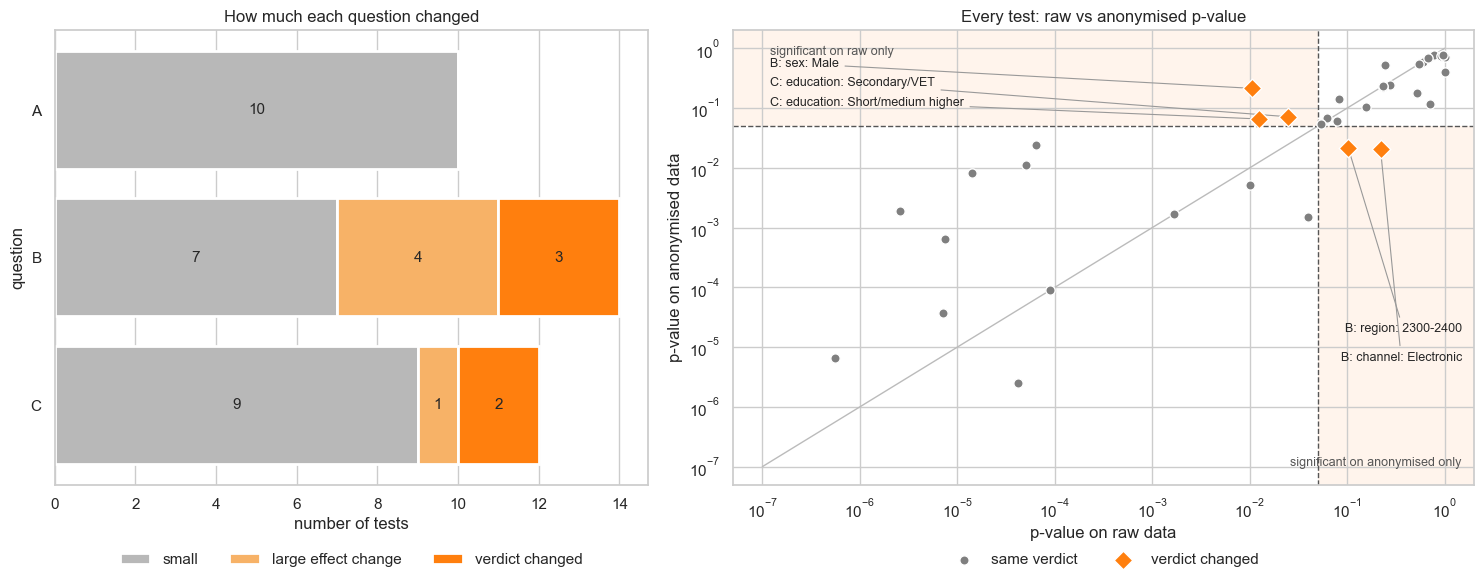

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
colors = {"small": "#b8b8b8", "large effect change": "#f7b267", "verdict changed": "#ff7f0e"}
tally_plot = tally.reindex(["A", "B", "C"])
left = np.zeros(len(tally_plot))
for lab in LABELS:
    vals = tally_plot[lab].values
    ax.barh(tally_plot.index, vals, left=left, color=colors[lab], edgecolor="white", linewidth=2, label=lab)
    for i, v in enumerate(vals):
        if v:
            ax.text(left[i] + v / 2, i, str(int(v)), ha="center", va="center", fontsize=11)
    left += vals
ax.invert_yaxis(); ax.set_xlabel("number of tests"); ax.set_ylabel("question"); ax.grid(axis="y", visible=False)
ax.set_title("How much each question changed")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)

ax = axes[1]
FLOOR = 1e-7
d = checks.assign(x=checks["p raw"].clip(lower=FLOOR), y=checks["p anonymised"].clip(lower=FLOOR, upper=1))
same = d[d["label"] != "verdict changed"]
flip = d[d["label"] == "verdict changed"]
ax.fill_between([FLOOR / 2, ALPHA], ALPHA, 2, color="#ff7f0e", alpha=0.08, zorder=0, lw=0)
ax.fill_between([ALPHA, 2], FLOOR / 2, ALPHA, color="#ff7f0e", alpha=0.08, zorder=0, lw=0)
ax.text(1.2e-7, 1.1, "significant on raw only", fontsize=9, color="#555555", va="top")
ax.text(1.5, 9e-8, "significant on anonymised only", fontsize=9, color="#555555", ha="right", va="bottom")
ax.scatter(same["x"], same["y"], s=45, color="#7f7f7f", edgecolor="white", linewidth=1, label="same verdict", zorder=3)
ax.scatter(flip["x"], flip["y"], s=90, color="#ff7f0e", marker="D", edgecolor="white", linewidth=1, label="verdict changed", zorder=4)
arrow = dict(arrowstyle="-", color="#999999", lw=0.8)
lost = flip[flip["p raw"] < ALPHA]
new = flip[flip["p raw"] >= ALPHA]
for i, (_, r) in enumerate(lost.iterrows()):
    ax.annotate(f"{r['question']}: {r['term']}", (r["x"], r["y"]), xytext=(1.2e-7, 0.55 / 2.1 ** i), fontsize=9, va="center", arrowprops=arrow)
for i, (_, r) in enumerate(new.iterrows()):
    ax.annotate(f"{r['question']}: {r['term']}", (r["x"], r["y"]), xytext=(1.5, 2e-5 / 3 ** i), fontsize=9, ha="right", va="center", arrowprops=arrow)
ax.axvline(ALPHA, color="#555555", ls="--", lw=1); ax.axhline(ALPHA, color="#555555", ls="--", lw=1)
ax.plot([FLOOR, 1], [FLOOR, 1], color="#bbbbbb", lw=1, zorder=1)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(FLOOR / 2, 2); ax.set_ylim(FLOOR / 2, 2)
ax.set_xlabel("p-value on raw data"); ax.set_ylabel("p-value on anonymised data")
ax.set_title("Every test: raw vs anonymised p-value")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout(); plt.show()

### Effect sizes
Each line connects a test's effect size on the raw data to the anonymised data. A long line means the anonymisation moved the effect, and a single orange marker means the two are identical.

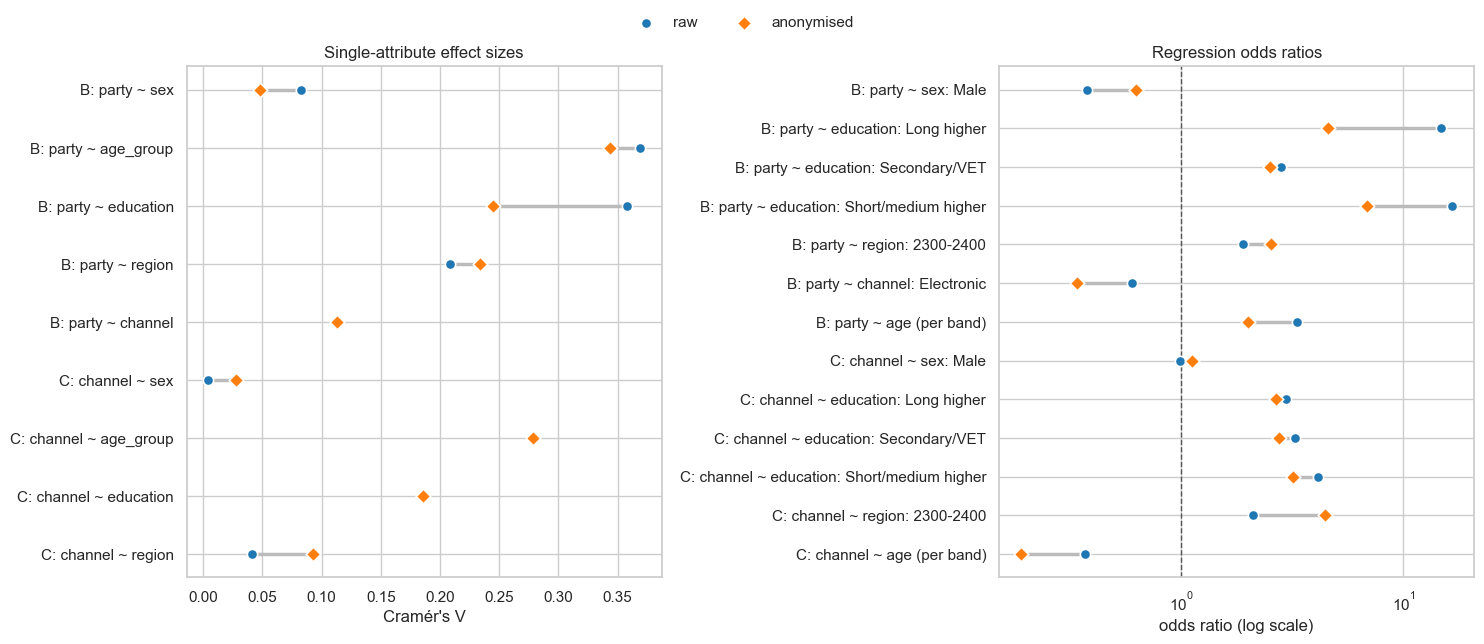

In [20]:
eff = pd.concat([pd.concat({k: t["Cramer's V"] for k, t in tab.items()}, axis=1).assign(question=q)
                 for q, tab in [("B: party", B), ("C: channel", C_assoc)]]).rename_axis("attribute").reset_index()
eff["label"] = eff["question"] + " ~ " + eff["attribute"]
eff = eff.iloc[::-1].reset_index(drop=True)

odds = pd.concat({"B: party": side_by_side(B_logit, ["OR"]), "C: channel": side_by_side(C_logit, ["OR"])})
odds.columns = ["raw", "anonymised"]
odds = odds.dropna().reset_index()
odds["label"] = odds["level_0"] + " ~ " + odds["level_1"].map(pretty)
odds = odds.iloc[::-1].reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, d, xlabel, title in [(axes[0], eff, "Cramér's V", "Single-attribute effect sizes"),
                             (axes[1], odds, "odds ratio (log scale)", "Regression odds ratios")]:
    ax.hlines(range(len(d)), d["raw"], d["anonymised"], color="#bbbbbb", lw=2.5, zorder=1)
    for name, style in STYLE.items():
        ax.scatter(d[name], range(len(d)), s=55, label=name, edgecolor="white", linewidth=1.2, zorder=3, **style)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d["label"]); ax.set_xlabel(xlabel); ax.set_title(title)
axes[1].set_xscale("log"); axes[1].axvline(1, color="#555555", ls="--", lw=1)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

## 7. Conclusions

### Answers to the three questions

| Question | Raw data | Anonymised data | Same answer? |
|---|---|---|---|
| **(A)** Survey vs official results | No significant difference, electronic or paper | No significant difference, electronic or paper | **Yes** |
| **(B)** Party vs demographics | Age, education and region differ significantly. Sex and channel do not | Age, education and region differ significantly. Sex and channel do not | **Yes** |
| **(C)** Channel vs demographics | Only age differs significantly | Only age differs significantly | **Yes** |

**(A)** The Red share is 28.1 % in the survey vs 31.9 % officially for e-votes, and 39.6 % (raw) or 39.7 % (anonymised) vs 34.8 % for paper votes. The largest gap is paper votes in region 2300-2400, about 50 % vs 39.6 % (p = 0.08 raw, 0.06 anonymised). Neither survives correction for the number of groups (Holm p = 0.39 and 0.31).

**(B)** In both datasets, Red voters are older, more educated and more common in region 2300-2400.

**(C)** In both datasets, e-voters are younger: about 47 % of the 20-39 band vote online, against about 14 % of the 60+ band.

Section 5 adds what only the raw data can show. ZIP is significantly related to party (Holm p = 0.003) but not to channel. Marital status and citizenship are not significant for either outcome. No single ZIP differs significantly from its official result.

### Are the differences too large?
**No question's answer changes: 0 of the 18 main tests change verdict, so by the rule set at the top the differences are not too large.** Some differences are large, though, and they are written out here.

| Where | Difference | Assessment |
|---|---|---|
| A, multinomial test | p falls from 0.51 to 0.18 (paper) and 0.71 to 0.12 (all votes) | Accepted. The verdict holds. It happens because the release has no invalid votes, and invalid votes can no longer be analysed. |
| B, education | Cramér's V 0.36 → 0.25, rank effect −0.38 → −0.25 | **Large, accepted.** Education stays significant (Holm p = 0.024), but its strength is understated. |
| B regression, sex | OR 0.38 → 0.63, p 0.011 → 0.21 | **Verdict changed.** The anonymised data cannot show that men vote Red less at the same age and education. |
| B regression, channel and region | p 0.22 → 0.020 and 0.10 → 0.021 | **Verdict changed: false new effects.** Do not report them from the anonymised data. |
| B regression, education | OR 14.9 → 4.6 and 16.7 → 6.9 | **Large, accepted.** Still significant, in the same direction. |
| C regression, education | p 0.024 → 0.072 and 0.012 → 0.066 | **Verdict changed, narrowly.** The odds ratios barely move (3.2 → 2.8, 4.1 → 3.2), so this is a small loss of precision around 0.05. |
| C regression, region and age | region OR 2.1 → 4.4, age OR 0.37 → 0.19 | **Exaggerated.** See below. |

**Why the regressions change more than the single tests.**
* The party swaps keep the counts per channel and region, so those columns stay intact, while the links between party and age, education and sex get weaker. That likely explains why the regression shifts weight onto channel and region and produces the false effects in question B.
* In question C, party is not involved, so the single-attribute tests for age and education are identical in both datasets.
* All 10 blanked regions are e-voters aged 40+, and they had to be left out of the channel regression, which leaves fewer older e-voters. The check in section 4 confirms this causes the inflated age effect: without region in the model, all 200 rows stay in and the age effect is almost identical (OR 0.43 raw vs 0.41 anonymised).

### What this means in practice
* **Use the anonymised data for:** the answers to A, B and C from the single-attribute tests, and comparisons with the official results.
* **Do not rely on it for:** adjusted effects in the regressions, especially sex, channel and region for party, or the size of the region and age effects for channel.

### Limits
* The tolerance for differences was set knowing from earlier comparisons that the regressions change more. The main-test rule was chosen because those tests answer the questions directly; a stricter rule that counts regression terms would call five differences too large.
* The raw data here is already recoded to the release's groups, so this comparison shows the effect of blanking and swapping. The recoding has its own cost, such as hiding ZIP-level detail.
* The party swap is a single random draw, and the code behind the anonymised file is not in the repository, so it is unknown how typical these results are.
* The sample is small (n = 200, 64 e-voters), so results near p = 0.05 can move easily in either dataset.